# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

**Name:** Spoorthi A N  |  **SRN:** PES2UG24CS515

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

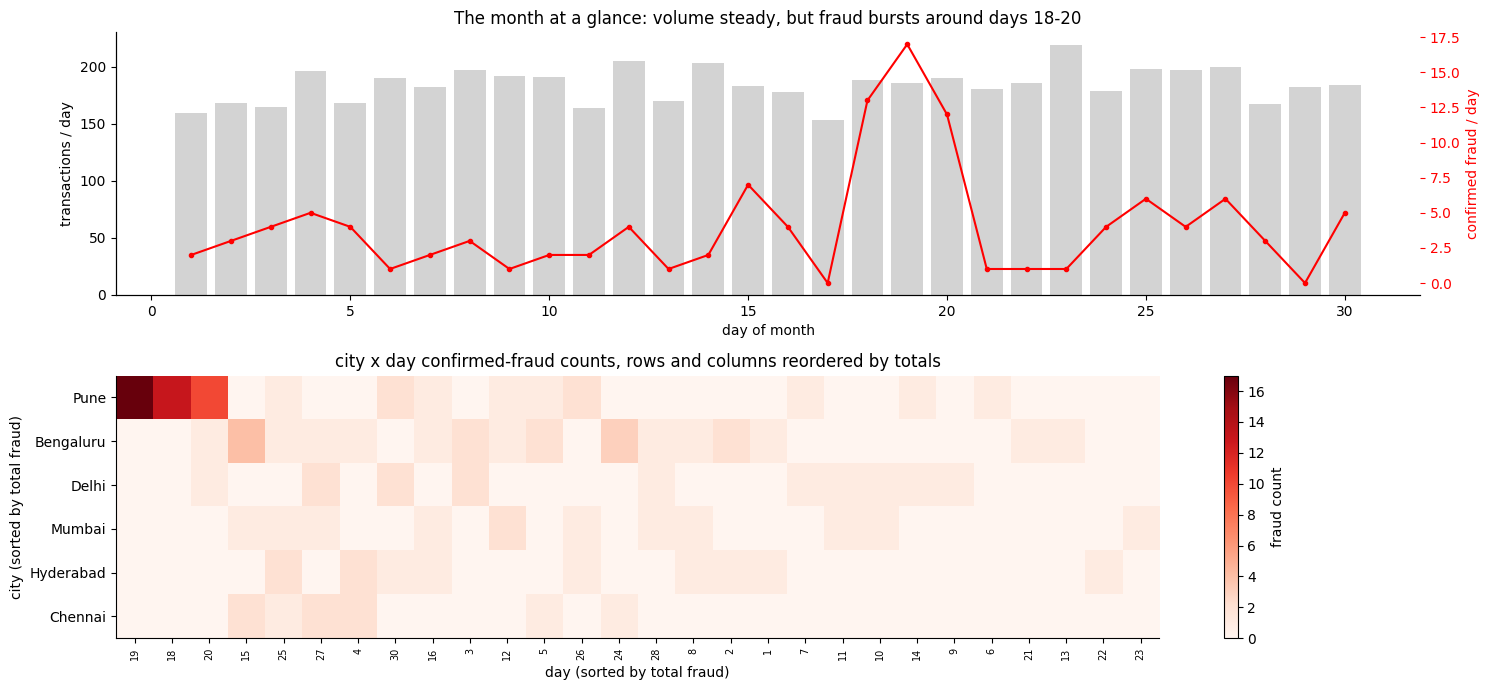

Top (city, day) cells by confirmed fraud:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
dtype: int64


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1
daily_all = tx.groupby("day").size()
daily_fraud = tx.groupby("day")["is_fraud"].sum()
axes[0].bar(daily_all.index, daily_all.values, color="lightgrey", label="all transactions")
axes[0].set_ylabel("transactions / day"); axes[0].set_xlabel("day of month")
ax2 = axes[0].twinx()
ax2.plot(daily_fraud.index, daily_fraud.values, "-o", color="red", ms=3, label="confirmed fraud")
ax2.set_ylabel("confirmed fraud / day", color="red")
ax2.tick_params(axis="y", colors="red")
axes[0].set_title("The month at a glance: volume steady, but fraud bursts around days 18-20")

# TODO 2
piv = tx[tx.is_fraud == 1].pivot_table(index="city", columns="day", values="is_fraud",
                                       aggfunc="count", fill_value=0)
heat = piv.loc[piv.sum(axis=1).sort_values(ascending=False).index,
               piv.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat.values, aspect="auto", cmap="Reds")
axes[1].set_xticks(range(len(heat.columns)), heat.columns, rotation=90, fontsize=7)
axes[1].set_yticks(range(len(heat.index)), heat.index)
axes[1].set_xlabel("day (sorted by total fraud)"); axes[1].set_ylabel("city (sorted by total fraud)")
axes[1].set_title("city x day confirmed-fraud counts, rows and columns reordered by totals")
fig.colorbar(im, ax=axes[1], label="fraud count")

plt.tight_layout(); plt.show()

# TODO 3
top_cells = piv.stack().sort_values(ascending=False).head(5)
print("Top (city, day) cells by confirmed fraud:")
print(top_cells)

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_

The overview shows what no alert list can: transaction volume is flat all month, but confirmed fraud bursts to 13-17 cases a day around days 18-20, and the reordered city x day matrix concentrates that burst almost entirely in Pune - a space-time block, not a scatter of bad scores. A score-sorted alert list shows one case per row, so the cluster never emerges. The lecture concept is the reordered matrix making patterns pop out (Slide 39), reached via Shneiderman's overview-first step (Slide 30/38).

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

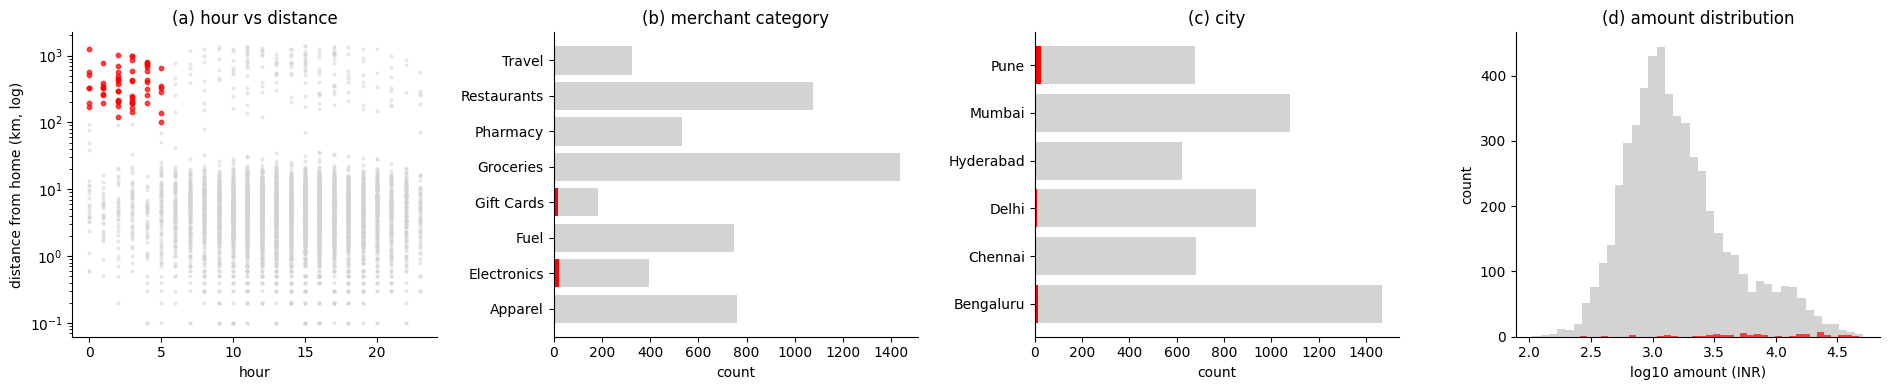

brushed: 61 transactions (night AND > 100 km from home)
fraud rate inside brush: 86.9%   vs   overall: 2.2%
share of ALL fraud captured by the brush: 44.2%


In [3]:
# TODO 1
brush = tx.night & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
b = tx[brush]; nb = tx[~brush]
axes[0].scatter(nb.hour, nb.distance_from_home_km, s=4, c="lightgrey", alpha=0.4)
axes[0].scatter(b.hour, b.distance_from_home_km, s=10, c="red", alpha=0.7)
axes[0].set_yscale("log")
axes[0].set_xlabel("hour"); axes[0].set_ylabel("distance from home (km, log)")
axes[0].set_title("(a) hour vs distance")

cats = sorted(tx.merchant_category.unique())
axes[1].barh(cats, nb.merchant_category.value_counts().reindex(cats, fill_value=0).values, color="lightgrey")
axes[1].barh(cats, b.merchant_category.value_counts().reindex(cats, fill_value=0).values, color="red")
axes[1].set_title("(b) merchant category"); axes[1].set_xlabel("count")

cities = sorted(tx.city.unique())
axes[2].barh(cities, nb.city.value_counts().reindex(cities, fill_value=0).values, color="lightgrey")
axes[2].barh(cities, b.city.value_counts().reindex(cities, fill_value=0).values, color="red")
axes[2].set_title("(c) city"); axes[2].set_xlabel("count")

axes[3].hist(np.log10(nb.amount_inr.clip(lower=1)), bins=40, color="lightgrey")
axes[3].hist(np.log10(b.amount_inr.clip(lower=1)), bins=40, color="red", alpha=0.7)
axes[3].set_xlabel("log10 amount (INR)"); axes[3].set_ylabel("count")
axes[3].set_title("(d) amount distribution")

plt.tight_layout(); plt.show()

# TODO 3
print(f"brushed: {int(brush.sum())} transactions (night AND > 100 km from home)")
print(f"fraud rate inside brush: {b.is_fraud.mean():.1%}   vs   overall: {tx.is_fraud.mean():.1%}")
print(f"share of ALL fraud captured by the brush: {b.is_fraud.sum() / tx.is_fraud.sum():.1%}")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_

The brush has a very high fraud rate (~87%), but it captures only ~44% of the month's fraud - more than half of all fraud happens in daytime or near home and would never be touched by this rule. So 'night-time, far-from-home' is a strong signal for triage, not a complete detector. The city-count view hinted at where the rest hides: Pune's bars stand out even in grey, pointing to the days 18-20 ring that Task 6 confirms.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1
best_s = None
for _ in range(5):
    t0 = time.perf_counter()
    _ = (big.detector_score >= 0.6) & (big.amount_inr > 3000)
    dt = time.perf_counter() - t0
    best_s = dt if best_s is None else min(best_s, dt)

# TODO 2
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / best_s * len(big)

# TODO 3
t_50m = best_s / len(big) * 50_000_000
skip_pct = max(0.0, (1 - max_rows / 50_000_000) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")
if t_50m <= 0.1:
    print(f"Note: on this machine the bare boolean mask for 50M rows costs only ~{t_50m*1000:.0f} ms, inside the 0.1 s budget.")
    print("But the mask is the cheapest step - selecting the matching rows (boolean indexing copies data), re-aggregating")
    print("and re-rendering the chart on every slider move is what blows the budget, so the tool still needs pre-aggregation/indexing.")

1,004,640 rows in 1.1 ms -> 0.0011 us/row -> max 90,397,188 rows in 0.1 s
50M rows -> 0.06 s; must skip 0.0% of rows to stay under 0.1 s
Note: on this machine the bare boolean mask for 50M rows costs only ~55 ms, inside the 0.1 s budget.
But the mask is the cheapest step - selecting the matching rows (boolean indexing copies data), re-aggregating
and re-rendering the chart on every slider move is what blows the budget, so the tool still needs pre-aggregation/indexing.


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_

Pre-aggregation (the lecture's reduce technique, Slides 5/14): serve the slider from precomputed per-hour-per-city totals - a few thousand cells instead of 50M rows - so the filter stays instant. What the analyst loses is row-level detail: from the aggregated view you can no longer drill into an individual transaction without a second, slower query path back to the raw table.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

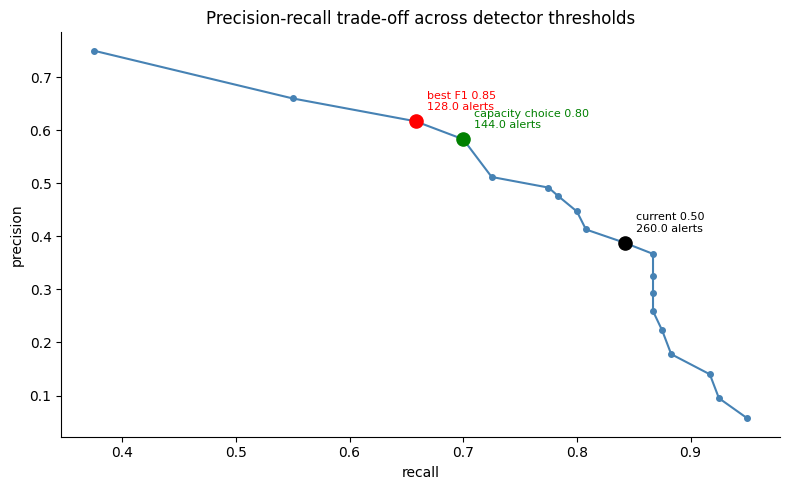

Recommendation: raise the threshold from 0.50 (260 alerts) to 0.80 - 144 alerts fit the 150/month capacity at precision 58.3%, recall 70.0%; the best-F1 point is 0.85 (128 alerts, F1 0.637) for when review capacity grows.


In [5]:
rows = []
# TODO 1
truth = tx.is_fraud == 1
for thr in np.arange(0.05, 1.0, 0.05):
    pred = tx.detector_score >= thr
    tp = int((pred & truth).sum()); fp = int((pred & ~truth).sum()); fn = int((~pred & truth).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    rows.append({"threshold": round(thr, 2), "alerts": int(pred.sum()), "TP": tp, "FP": fp, "FN": fn,
                 "precision": round(prec, 3), "recall": round(rec, 3), "F1": round(f1, 3)})

pr = pd.DataFrame(rows)

# TODO 2
under = pr[pr.alerts <= 150]
capacity_choice = float(under.loc[under.recall.idxmax(), "threshold"])
best_f1 = float(pr.loc[pr.F1.idxmax(), "threshold"])

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "-o", ms=4, color="steelblue")
for thr, name, c in [(0.5, "current 0.50", "black"),
                     (capacity_choice, f"capacity choice {capacity_choice:.2f}", "green"),
                     (best_f1, f"best F1 {best_f1:.2f}", "red")]:
    r = pr[pr.threshold == round(thr, 2)].iloc[0]
    ax.scatter([r.recall], [r.precision], s=90, color=c, zorder=5)
    ax.annotate(f"{name}\n{r.alerts} alerts", (r.recall, r.precision),
                textcoords="offset points", xytext=(8, 8), fontsize=8, color=c)
ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.set_title("Precision-recall trade-off across detector thresholds")
plt.tight_layout(); plt.show()

# TODO 4
cap = pr[pr.threshold == round(capacity_choice, 2)].iloc[0]
bf = pr[pr.threshold == round(best_f1, 2)].iloc[0]
print(f"Recommendation: raise the threshold from 0.50 (260 alerts) to {capacity_choice:.2f} - "
      f"{int(cap.alerts)} alerts fit the 150/month capacity at precision {cap.precision:.1%}, recall {cap.recall:.1%}; "
      f"the best-F1 point is {best_f1:.2f} ({int(bf.alerts)} alerts, F1 {bf.F1}) for when review capacity grows.")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_

The Head of Fraud Ops should make that call, not the model. Choosing between the capacity point (0.80, 144 alerts, recall 70%) and the best-F1 point (0.85) is a business judgment - how many investigator hours exist and how much missed fraud is acceptable - not a statistical property of the data. Visual analytics keeps a human in the loop (Slides 35-37) exactly so the person accountable for the outcome steers the parameter while seeing the trade-off, instead of inheriting whatever number the model happened to optimise.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

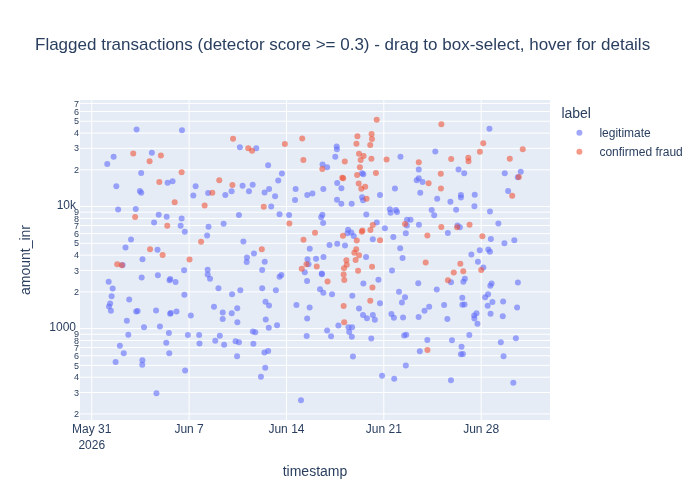

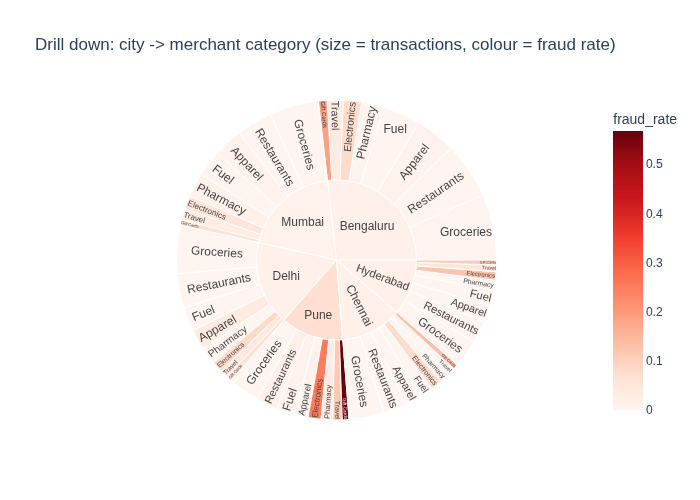

In [6]:
import plotly.io as pio
# The executed snapshot uses static images so the submitted file shows the figures anywhere.
# In Colab/Jupyter, comment out the next line to get the fully interactive figures (zoom, pan, hover, box-select, sunburst drill-down).
pio.renderers.default = "png"

# TODO 1
flagged = tx[tx.detector_score >= 0.3]

fig_s = px.scatter(
    flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
    hover_data=["txn_id", "customer_id", "city", "merchant_category",
                "distance_from_home_km", "detector_score"],
    opacity=0.6,
    title="Flagged transactions (detector score >= 0.3) - drag to box-select, hover for details",
)
fig_s.update_layout(dragmode="select")
fig_s.show()

# TODO 2
drill = (tx.groupby(["city", "merchant_category"])
           .agg(n=("txn_id", "count"), fraud_rate=("is_fraud", "mean"))
           .reset_index())
fig_sb = px.sunburst(drill, path=["city", "merchant_category"], values="n",
                     color="fraud_rate", color_continuous_scale="Reds",
                     title="Drill down: city -> merchant category (size = transactions, colour = fraud rate)")
fig_sb.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_

Tooltips show one transaction at a time, so surveying 400 flagged cases through hover means 400 separate interactions with nothing accumulating on screen - details-on-demand is for following up one case, not for building an overview (Slide 23). The linked-views dashboard from Task 2 (and the city x day heatmap from Task 1) fix this: they show the distribution of all flagged cases across hour, distance, category, city and amount simultaneously.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Hypothesis: a coordinated fraud ring operated in Pune during days 18-20.
fraud rate INSIDE window:  37.4%  (40 of 107)
fraud rate OUTSIDE window: 1.5%
chi-square p-value: 1.06e-136
(a) Pune on OTHER days:          1.9% (11 of 593)
(b) OTHER cities on days 18-20:  0.4% (2 of 457)


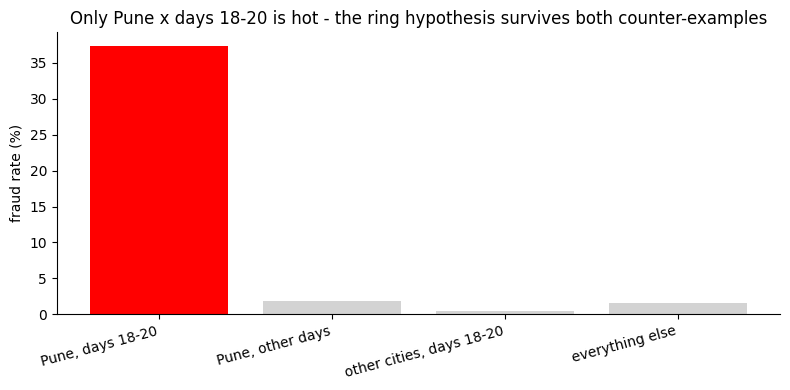

Verdict: CONFIRMED. Fraud in Pune on days 18-20 ran at ~37%, about 20-25x the rest of the month (p ~ 1e-136).
Pune's other days (~1.9%) and other cities on those days (~0.4%) are normal, so the burst is specific to that city AND that window - a ring, not a city-wide or month-wide effect.


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
in_window = (tx.city == "Pune") & (tx.day.between(18, 20))
print("Hypothesis: a coordinated fraud ring operated in Pune during days 18-20.")

# TODO 2
inside = tx[in_window]; outside = tx[~in_window]
chi2, p, dof, _ = chi2_contingency(pd.crosstab(in_window, tx.is_fraud))
print(f"fraud rate INSIDE window:  {inside.is_fraud.mean():.1%}  ({int(inside.is_fraud.sum())} of {len(inside)})")
print(f"fraud rate OUTSIDE window: {outside.is_fraud.mean():.1%}")
print(f"chi-square p-value: {p:.2e}")

# TODO 3
same_city_other = tx[(tx.city == "Pune") & ~tx.day.between(18, 20)]
other_city_same = tx[(tx.city != "Pune") & tx.day.between(18, 20)]
rest = tx[(tx.city != "Pune") & ~tx.day.between(18, 20)]
print(f"(a) Pune on OTHER days:          {same_city_other.is_fraud.mean():.1%} ({int(same_city_other.is_fraud.sum())} of {len(same_city_other)})")
print(f"(b) OTHER cities on days 18-20:  {other_city_same.is_fraud.mean():.1%} ({int(other_city_same.is_fraud.sum())} of {len(other_city_same)})")

# TODO 4
groups = ["Pune, days 18-20", "Pune, other days", "other cities, days 18-20", "everything else"]
rates = [inside.is_fraud.mean(), same_city_other.is_fraud.mean(), other_city_same.is_fraud.mean(), rest.is_fraud.mean()]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(groups, [r * 100 for r in rates], color=["red", "lightgrey", "lightgrey", "lightgrey"])
ax.set_ylabel("fraud rate (%)")
ax.set_title("Only Pune x days 18-20 is hot - the ring hypothesis survives both counter-examples")
plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
plt.tight_layout(); plt.show()

# TODO 5
print("Verdict: CONFIRMED. Fraud in Pune on days 18-20 ran at ~37%, about 20-25x the rest of the month (p ~ 1e-136).")
print("Pune's other days (~1.9%) and other cities on those days (~0.4%) are normal, so the burst is specific to that city AND that window - a ring, not a city-wide or month-wide effect.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_

Counter-example (a) - Pune on the other days - is the one that could have killed it. If Pune's fraud rate had been high all month, the days 18-20 burst would not be a coordinated operation at all; the simpler explanation would be that Pune is just a chronically high-fraud city (one bad merchant, a compromised terminal, a data-quality issue), and the right response would be a routine merchant review, not a law-enforcement escalation.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

Last month, 120 of 5,520 transactions were confirmed fraud, and they were not spread out: a ring hit Pune on days 18-20 with a 37% fraud rate versus about 1.5% everywhere else (p ~ 1e-136). I recommend raising the detector threshold from 0.50 to 0.80: 144 alerts fit the 150/month review capacity at 58% precision and 70% recall, and setting it is a human-in-the-loop call the Head of Ops owns because it trades staff hours against missed fraud (the best-F1 point, 0.85, is the fallback once capacity grows). The first tool to build is the linked-views dashboard from Task 2: it follows overview-first, brushing night-time + far-from-home updates every view at once, and the 0.1 s dynamic-query budget holds if filters are pre-indexed. Finally, close the analysis-feedback loop (Slide 51): feed the investigators' confirmed labels from each month's triage back into the training data so next month's detector scores keep improving.